# Inferensi Model Analisis Sentimen Ulasan Disney+

Antonius Vincent Jung - CACC012D6Y2282 - CAC-15

Notebook ini digunakan untuk menjalankan prediksi sentimen pada teks baru menggunakan tiga model yang telah dilatih sebelumnya:
- **Logistic Regression** dengan representasi TF-IDF (word + char n-gram)
- **Support Vector Machine (LinearSVC)** dengan representasi TF-IDF (word + char n-gram)
- **Bidirectional LSTM** dengan representasi sekuens berbasis tokenizer


## Install Library

In [4]:
!pip install pandas numpy scikit-learn nltk sastrawi tensorflow joblib scipy

## Import Library

In [5]:
import os
import re
import joblib
import numpy as np
import pandas as pd
from scipy.sparse import hstack

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Koneksi Google Drive dan Pemuatan Model

In [6]:
from google.colab import drive
drive.mount('/content/drive')

MODEL_DIR = '/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen'

# Verifikasi keberadaan seluruh file model
required_files = [
    'model_lr_optimized.pkl',
    'tfidf_word_lr.pkl',
    'tfidf_char_lr.pkl',
    'model_svm_optimized.pkl',
    'tfidf_word_svm.pkl',
    'tfidf_char_svm.pkl',
    'model_lstm_optimized.h5',
    'tokenizer_lstm_optimized.pkl',
    'label_encoder_optimized.pkl',
]

for fname in required_files:
    fpath = os.path.join(MODEL_DIR, fname)
    status = '[ADA]    ' if os.path.exists(fpath) else '[TIDAK ADA]'
    print(f'  {status} {fname}')

Mounted at /content/drive
  [ADA]     model_lr_optimized.pkl
  [ADA]     tfidf_word_lr.pkl
  [ADA]     tfidf_char_lr.pkl
  [ADA]     model_svm_optimized.pkl
  [ADA]     tfidf_word_svm.pkl
  [ADA]     tfidf_char_svm.pkl
  [ADA]     model_lstm_optimized.h5
  [ADA]     tokenizer_lstm_optimized.pkl
  [ADA]     label_encoder_optimized.pkl


In [7]:
# Pemuatan seluruh artefak model
print('Memuat model Logistic Regression...')
model_lr    = joblib.load(os.path.join(MODEL_DIR, 'model_lr_optimized.pkl'))
tfidf_word_lr = joblib.load(os.path.join(MODEL_DIR, 'tfidf_word_lr.pkl'))
tfidf_char_lr = joblib.load(os.path.join(MODEL_DIR, 'tfidf_char_lr.pkl'))
print('Model Logistic Regression dimuat.')

print('Memuat model SVM...')
model_svm     = joblib.load(os.path.join(MODEL_DIR, 'model_svm_optimized.pkl'))
tfidf_word_svm = joblib.load(os.path.join(MODEL_DIR, 'tfidf_word_svm.pkl'))
tfidf_char_svm = joblib.load(os.path.join(MODEL_DIR, 'tfidf_char_svm.pkl'))
print('Model SVM dimuat.')

print('Memuat model LSTM...')
model_lstm    = load_model(os.path.join(MODEL_DIR, 'model_lstm_optimized.h5'))
tokenizer     = joblib.load(os.path.join(MODEL_DIR, 'tokenizer_lstm_optimized.pkl'))
label_encoder = joblib.load(os.path.join(MODEL_DIR, 'label_encoder_optimized.pkl'))
print('Model LSTM dimuat.')

# Parameter sekuens LSTM
MAX_LEN = 150

print(f'Kelas sentimen: {label_encoder.classes_}')

Memuat model Logistic Regression...
Model Logistic Regression dimuat.
Memuat model SVM...
Model SVM dimuat.
Memuat model LSTM...


Model LSTM dimuat.
Kelas sentimen: ['negative' 'neutral' 'positive']


## Fungsi Preprocessing Teks

Fungsi preprocessing di bawah ini identik dengan yang digunakan pada tahap pelatihan. Konsistensi pipeline preprocessing merupakan hal yang krusial untuk memastikan representasi teks yang sama antara tahap pelatihan dan inferensi.

### Slang Words Dictionary

In [8]:
slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "plisss": "tolong", "bgttt": "banget", "indo": "indonesia", "bgtt": "banget", "ad": "ada", "rv": "redvelvet", "plis": "tolong", "pls": "tolong", "cr": "sumber", "cod": "bayar ditempat", "adlh": "adalah", "afaik": "as far as i know", "ahaha": "haha", "aj": "saja", "ak": "saya", "alay": "norak", "alow": "halo", "ancur": "hancur", "anjrit": "anjing", "anter": "antar", "apasih": "apa sih", "apes": "sial", "aps": "apa", "aq": "saya", "asbun": "asal bunyi", "aseekk": "asyik", "asekk": "asyik", "asem": "asam", "astul": "asal tulis", "ato": "atau", "awak": "saya", "ay": "sayang", "ayank": "sayang", "b4": "sebelum", "bakalan": "akan", "bangedh": "banget", "basbang": "basi", "bcanda": "bercanda", "bdg": "bandung", "begajulan": "nakal", "beliin": "belikan", "bentar": "sebentar", "bete": "bosan", "beud": "banget", "bg": "abang", "bgmn": "bagaimana", "bgt": "banget", "bijimane": "bagaimana", "bkl": "akan", "bknnya": "bukannya", "blh": "boleh", "bln": "bulan", "blum": "belum", "bnci": "benci", "bodor": "lucu", "bokap": "ayah", "bokis": "bohong", "boljug": "boleh juga", "bonek": "bocah nekat", "boyeh": "boleh", "br": "baru", "brg": "bareng", "bro": "saudara laki-laki", "bru": "baru", "bs": "bisa", "bsen": "bosan", "bt": "buat", "btw": "ngomong-ngomong", "buaya": "tidak setia", "bw": "bawa", "bwt": "buat", "byk": "banyak", "byrin": "bayarkan", "cabal": "sabar", "cadas": "keren", "calo": "makelar", "can": "belum", "capcus": "pergi", "caper": "cari perhatian", "ce": "cewek", "cemen": "penakut", "cengengesan": "tertawa", "cepet": "cepat", "cew": "cewek", "chuyunk": "sayang", "cimeng": "ganja", "ciyh": "sih", "ckepp": "cakep", "ckp": "cakep", "cmiiw": "correct me if im wrong", "cmpur": "campur", "cong": "banci", "conlok": "cinta lokasi", "cowwyy": "maaf", "cp": "siapa", "cpe": "capek", "cppe": "capek", "cucok": "cocok", "cuex": "cuek", "cups": "culun", "curcol": "curahan hati colongan", "cwek": "cewek", "cyin": "cinta", "d": "di", "dah": "deh", "dapet": "dapat", "de": "adik", "dek": "adik", "demen": "suka", "deyh": "deh", "dgn": "dengan", "diancurin": "dihancurkan", "dimaafin": "dimaafkan", "dimintak": "diminta", "disono": "di sana", "dket": "dekat", "dkk": "dan kawan-kawan", "dll": "dan lain-lain", "dlu": "dulu", "dngn": "dengan", "dodol": "bodoh", "doku": "uang", "dongs": "dong", "dpt": "dapat", "dri": "dari", "drmn": "darimana", "drtd": "dari tadi", "dst": "dan seterusnya", "dtg": "datang", "duh": "aduh", "duren": "durian", "egp": "emang gue pikirin", "eke": "aku", "elu": "kamu", "emangnya": "memangnya", "emng": "memang", "endak": "tidak", "gaa": "tidak", "enggak": "tidak", "envy": "iri", "ex": "mantan", "folbek": "follow back", "fyi": "sebagai informasi", "gaada": "tidak ada uang", "gk": "tidak", "gag": "tidak", "gaje": "tidak jelas", "gak papa": "tidak apa-apa", "gan": "juragan", "gaptek": "gagap teknologi", "gatek": "gagap teknologi", "gawe": "kerja", "gbs": "tidak bisa", "gebetan": "orang yang disuka", "geje": "tidak jelas", "ghiy": "lagi", "gile": "gila", "gimana": "bagaimana", "githu": "gitu", "gj": "tidak jelas", "gmana": "bagaimana", "gn": "begini", "goblok": "bodoh", "gokil": "gila", "gombal": "suka merayu", "gpl": "tidak pakai lama", "gpp": "tidak apa-apa", "gretong": "gratis", "gt": "begitu", "gtw": "tidak tahu", "gue": "saya", "guys": "teman-teman", "gws": "cepat sembuh", "hellow": "halo", "helow": "halo", "hi": "hai", "hlng": "hilang", "hnya": "hanya", "hrs": "harus", "huft": "mengeluh", "idk": "saya tidak tahu", "ilfeel": "tidak suka", "imba": "jago sekali", "info": "informasi", "itung": "hitung", "isengin": "bercanda", "iyala": "iya lah", "iyo": "iya", "jablay": "jarang dibelai", "jadul": "jaman dulu", "jancuk": "anjing", "jd": "jadi", "jdikan": "jadikan", "jg": "juga", "jgn": "jangan", "jijay": "jijik", "jkt": "jakarta", "jnj": "janji", "jth": "jatuh", "jwb": "jawab", "ka": "kakak", "kacian": "kasihan", "kaga": "tidak", "kaka": "kakak", "kamuh": "kamu", "kamyu": "kamu", "kau": "kamu", "kbar": "kabar", "kcian": "kasihan", "keburu": "terlanjur", "kek": "seperti", "keknya": "kayaknya", "keliatan": "kelihatan", "keneh": "masih", "kepikiran": "terpikirkan", "kepo": "mau tahu urusan orang", "kere": "tidak punya uang", "kesian": "kasihan", "ketauan": "ketahuan", "keukeuh": "keras kepala", "khan": "kan", "kk": "kakak", "klian": "kalian", "klo": "kalau", "kluarga": "keluarga", "klwrga": "keluarga", "kmari": "kemari", "kmpus": "kampus", "kn": "kan", "knl": "kenal", "knpa": "kenapa", "kog": "kok", "kompi": "komputer", "koq": "kok", "kpd": "kepada", "kptsan": "keputusan", "krik": "garing", "krn": "karena", "ktauan": "ketahuan", "ktny": "katanya", "kudu": "harus", "kuq": "kok", "ky": "seperti", "kykny": "kayanya", "lambreta": "lambat", "lbur": "libur", "lekong": "laki-laki", "lg": "lagi", "lgkp": "lengkap", "lht": "lihat", "lmyan": "lumayan", "lngkp": "lengkap", "loch": "loh", "lol": "tertawa", "lom": "belum", "loupz": "cinta", "lowh": "kamu", "lu": "kamu", "luchu": "lucu", "luff": "cinta", "luph": "cinta", "lw": "kamu", "lwt": "lewat", "maaciw": "terima kasih", "macem-macem": "macam-macam", "madesu": "masa depan suram", "maen": "main", "mak": "ibu", "makasih": "terima kasih", "malah": "bahkan", "malu2in": "memalukan", "mamz": "makan", "manies": "manis", "mantep": "mantap", "mba": "mbak", "mending": "lebih baik", "mgkn": "mungkin", "mhn": "mohon", "milis": "mailing list", "mksd": "maksud", "mls": "malas", "mnt": "minta", "moge": "motor gede", "mokat": "mati", "mosok": "masa", "msh": "masih", "mskpn": "meskipun", "msng2": "masing-masing", "muahal": "mahal", "mumet": "pusing", "muna": "munafik", "muup": "maaf", "muuv": "maaf", "nal": "kenal", "nangis": "menangis", "naon": "apa", "naq": "anak", "narsis": "bangga pada diri sendiri", "nax": "anak", "ndak": "tidak", "ndut": "gendut", "nelfon": "menelepon", "ngabis2in": "menghabiskan", "ngakak": "tertawa", "ngambek": "marah", "ngampus": "pergi ke kampus", "ngantri": "mengantri", "ngapain": "sedang apa", "ngaruh": "berpengaruh", "ngawur": "berbicara sembarangan", "ngeh": "sadar", "ngelamar": "melamar", "ngeliat": "melihat", "ngentotin": "senggama", "ngerti": "mengerti", "nggak": "tidak", "nggk": "tidak", "ngikut": "ikut", "nginep": "menginap", "ngisi": "mengisi", "ngocol": "lucu", "ngomongin": "membicarakan", "ngumpul": "berkumpul", "ni": "ini", "nyasar": "tersesat", "nyariin": "mencari", "nyiram": "menyiram", "nyok": "ayo", "ok": "ok", "priksa": "periksa", "pro": "profesional", "psn": "pesan", "psti": "pasti", "puanas": "panas", "qt": "kita", "rame": "ramai", "re": "reply", "ref": "referensi", "rehab": "rehabilitasi", "rempong": "sulit", "repp": "balas", "rhs": "rahasia", "rmh": "rumah", "ru": "baru", "ruko": "rumah toko", "ruz": "terus", "saia": "saya", "salting": "salah tingkah", "sampe": "sampai", "samsek": "sama sekali", "sapose": "siapa", "sbb": "sebagai berikut", "sbh": "sebuah", "sbnrny": "sebenarnya", "scr": "secara", "sdgkn": "sedangkan", "sdkt": "sedikit", "sgt": "sangat", "shg": "sehingga", "siech": "sih", "sinetron": "sinema elektronik", "siramin": "siramkan", "sj": "saja", "skalian": "sekalian", "sklh": "sekolah", "skt": "sakit", "slesai": "selesai", "sll": "selalu", "slma": "selama", "slsai": "selesai", "smpt": "sempat", "smw": "semua", "sndiri": "sendiri", "songong": "sombong", "sory": "maaf", "sosbud": "sosial-budaya", "sowry": "maaf", "spd": "sepeda", "sprti": "seperti", "spy": "supaya", "stelah": "setelah", "suk": "masuk", "sumpek": "sempit", "syg": "sayang", "tajir": "kaya", "tau": "tahu", "taw": "tahu", "td": "tadi", "tdk": "tidak", "teh": "kakak perempuan", "telat": "terlambat", "telmi": "telat berpikir", "temen": "teman", "tengil": "menyebalkan", "tepar": "terkapar", "tggu": "tunggu", "tgu": "tunggu", "thankz": "terima kasih", "thn": "tahun", "tks": "terima kasih", "tlp": "telepon", "tls": "tulis", "tmbah": "tambah", "tmen2": "teman-teman", "tmpah": "tumpah", "tmpt": "tempat", "tngu": "tunggu", "tnyta": "ternyata", "tp": "tapi", "tq": "terima kasih", "trgntg": "tergantung", "trims": "terima kasih", "cb": "coba", "y": "ya", "munfik": "munafik", "sma": "sama", "ngehe": "kesal", "mz": "mas", "sadaar": "sadar", "zonk": "bodoh", "rights": "benar", "ngumpet": "sembunyi", "hardcore": "keras", "solve": "solusi", "watuk": "batuk", "ngebully": "intimidasi", "masy": "masyarakat", "still": "masih", "tauk": "tahu", "mbual": "bual", "faktakta": "fakta", "sohib": "teman", "trlalu": "terlalu", "nyela": "cela", "heters": "pembenci", "most": "paling", "ikon": "lambang", "light": "terang", "setting": "atur", "next": "lanjut", "waspadalah": "waspada", "gantengsaya": "ganteng", "nyerang": "serang", "nipu": "tipu", "ktipu": "tipu", "jentelmen": "berani", "buangbuang": "buang", "tsangka": "tersangka", "kurng": "kurang", "less": "kurang", "koar": "teriak", "paranoid": "takut", "problem": "masalah", "tahi": "kotoran", "tirani": "tiran", "tilep": "tilap", "happy": "bahagia", "tak": "tidak", "penertiban": "tertib", "mnolak": "tolak", "trending": "trend", "taik": "tahi", "wkwkkw": "tertawa", "eror": "error", "g": "tidak", "ga": "tidak", "gak": "tidak", "kagak": "tidak", "kalo": "kalau", "udah": "sudah", "uda": "sudah", "ud": "sudah", "bener": "benar", "mantap": "mantap", "keren": "keren"}

def fix_slangwords(text):
    words = text.split()
    return ' '.join([slangwords.get(w.lower(), w) for w in words])

print(f'Slang dictionary loaded: {len(slangwords)} kata')

Slang dictionary loaded: 482 kata


### Cleaning, Tokenisasi, dan Stemming

In [9]:
def cleaning_text(text):
    text = str(text)
    text = re.sub(r'@[A-Za-z0-9]+', ' ', text)
    text = re.sub(r'#[A-Za-z0-9]+', ' ', text)
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[0-9]+', ' ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)  # Pertahankan 2 huruf (mis: "baguss" → "baguss") agar lebih informatif
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenizing_text(text):
    return word_tokenize(text)

STOPWORDS = set(stopwords.words('indonesian') + stopwords.words('english'))
# JANGAN hapus kata negasi — penting untuk sentimen!
negation_words = {'tidak', 'bukan', 'jangan', 'tanpa', 'belum', 'tak', 'ga', 'gak', 'nggak', 'ndak', 'tiada'}
STOPWORDS -= negation_words
STOPWORDS.update(['iya','yaa','nya','na','sih','ku','ya','loh','kah','deh','woi','woii','woy','anjay'])

def filtering_text(text):
    return [w for w in text if w not in STOPWORDS and len(w) > 1]

# Lazy stemmer singleton
_stemmer = None
def get_stemmer():
    global _stemmer
    if _stemmer is None:
        _stemmer = StemmerFactory().create_stemmer()
    return _stemmer

def stemming_text(words):
    stemmer = get_stemmer()
    return [stemmer.stem(w) for w in words]


In [10]:
def preprocess_text(raw_text):
    text = cleaning_text(raw_text) # Pembersihan teks (cleaning)
    text = fix_slangwords(text) # Normalisasi kata tidak baku (slang fix)
    tokens = word_tokenize(text) # Tokenisasi
    tokens = filtering_text(tokens) # Penghapusan stopword
    tokens = stemming_text(tokens) # Stemming
    return ' '.join(tokens) # Penggabungan token menjadi string


# Uji pipeline preprocessing
contoh = "Aplikasi Disney+ ini bgt bagus sih tapi kok sering loading lama bgt, gak bisa streaming lancar"
hasil  = preprocess_text(contoh)
print(f'Teks asli  : {contoh}')
print(f'Teks proses: {hasil}')

Teks asli  : Aplikasi Disney+ ini bgt bagus sih tapi kok sering loading lama bgt, gak bisa streaming lancar
Teks proses: aplikasi disney banget bagus loading banget tidak streaming lancar


## Fungsi Inferensi per Model

In [11]:
def predict_lr(raw_text):
    # Melakukan prediksi sentimen menggunakan model Logistic Regression.
    processed = preprocess_text(raw_text)

    # Transformasi fitur menggunakan TF-IDF yang telah dilatih
    feat_word = tfidf_word_lr.transform([processed])
    feat_char = tfidf_char_lr.transform([processed])
    feat_combined = hstack([feat_word, feat_char])

    label = model_lr.predict(feat_combined)[0]
    proba = model_lr.predict_proba(feat_combined)[0]
    proba_dict = dict(zip(model_lr.classes_, proba))

    return {
        'teks_asli'       : raw_text,
        'teks_proses'     : processed,
        'prediksi'        : label,
        'probabilitas'    : {k: round(float(v), 4) for k, v in proba_dict.items()},
    }


def predict_svm(raw_text):
    # Melakukan prediksi sentimen menggunakan model SVM (LinearSVC).
    processed = preprocess_text(raw_text)

    feat_word = tfidf_word_svm.transform([processed])
    feat_char = tfidf_char_svm.transform([processed])
    feat_combined = hstack([feat_word, feat_char])

    label = model_svm.predict(feat_combined)[0]

    # LinearSVC menggunakan decision_function sebagai pengganti probabilitas
    scores = model_svm.decision_function(feat_combined)[0]
    scores_dict = dict(zip(model_svm.classes_, scores))

    return {
        'teks_asli'       : raw_text,
        'teks_proses'     : processed,
        'prediksi'        : label,
        'decision_score'  : {k: round(float(v), 4) for k, v in scores_dict.items()},
    }


def predict_lstm(raw_text):
    # Melakukan prediksi sentimen menggunakan model Bidirectional LSTM.
    processed = preprocess_text(raw_text)

    # Konversi teks ke sekuens indeks dan padding
    seq = tokenizer.texts_to_sequences([processed])
    pad = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')

    proba = model_lstm.predict(pad, verbose=0)[0]
    idx   = int(np.argmax(proba))
    label = label_encoder.classes_[idx]
    proba_dict = dict(zip(label_encoder.classes_, proba))

    return {
        'teks_asli'       : raw_text,
        'teks_proses'     : processed,
        'prediksi'        : label,
        'probabilitas'    : {k: round(float(v), 4) for k, v in proba_dict.items()},
    }


## Fungsi Inferensi Gabungan (Ketiga Model Sekaligus)

In [12]:
def predict_all(raw_text, verbose=True):
    # Menjalankan prediksi sentimen menggunakan ketiga model secara bersamaan dan menampilkan hasil perbandingan.
    hasil_lr   = predict_lr(raw_text)
    hasil_svm  = predict_svm(raw_text)
    hasil_lstm = predict_lstm(raw_text)

    if verbose:
        print('=' * 60)
        print('HASIL INFERENSI ANALISIS SENTIMEN')
        print('=' * 60)
        print(f'Teks asli    : {raw_text}')
        print(f'Teks proses  : {hasil_lr["teks_proses"]}')
        print('-' * 60)
        print(f'[LR]   Prediksi : {hasil_lr["prediksi"].upper():<10} | '
              f'Probabilitas: {hasil_lr["probabilitas"]}')
        print(f'[SVM]  Prediksi : {hasil_svm["prediksi"].upper():<10} | '
              f'Decision score: {hasil_svm["decision_score"]}')
        print(f'[LSTM] Prediksi : {hasil_lstm["prediksi"].upper():<10} | '
              f'Probabilitas: {hasil_lstm["probabilitas"]}')
        print('=' * 60)

    return {
        'logistic_regression' : hasil_lr,
        'svm'                 : hasil_svm,
        'lstm'                : hasil_lstm,
    }

## Contoh Inferensi Teks Tunggal

In [13]:
# ── Contoh 1: Ulasan Positif ──
teks_positif = "Disney Plus benar-benar luar biasa! Kontennya sangat lengkap dan gambarnya jernih banget. Puas sekali berlangganan."
hasil = predict_all(teks_positif)

HASIL INFERENSI ANALISIS SENTIMEN
Teks asli    : Disney Plus benar-benar luar biasa! Kontennya sangat lengkap dan gambarnya jernih banget. Puas sekali berlangganan.
Teks proses  : disney plus konten lengkap gambar jernih banget puas langgan
------------------------------------------------------------
[LR]   Prediksi : POSITIVE   | Probabilitas: {'negative': 0.0, 'neutral': 0.0, 'positive': 1.0}
[SVM]  Prediksi : POSITIVE   | Decision score: {'negative': -4.5355, 'neutral': -0.6705, 'positive': 2.7385}
[LSTM] Prediksi : POSITIVE   | Probabilitas: {'negative': 0.0192, 'neutral': 0.016, 'positive': 0.9647}


In [14]:
# ── Contoh 2: Ulasan Negatif ──
teks_negatif = "Aplikasi ini sangat mengecewakan. Sering error, tidak bisa login, dan customer service tidak membantu sama sekali. Buang-buang uang."
hasil = predict_all(teks_negatif)

HASIL INFERENSI ANALISIS SENTIMEN
Teks asli    : Aplikasi ini sangat mengecewakan. Sering error, tidak bisa login, dan customer service tidak membantu sama sekali. Buang-buang uang.
Teks proses  : aplikasi kecewa error tidak login customer service tidak bantu buang buang uang
------------------------------------------------------------
[LR]   Prediksi : NEGATIVE   | Probabilitas: {'negative': 1.0, 'neutral': 0.0, 'positive': 0.0}
[SVM]  Prediksi : NEGATIVE   | Decision score: {'negative': 5.8656, 'neutral': -3.2474, 'positive': -6.7122}
[LSTM] Prediksi : NEGATIVE   | Probabilitas: {'negative': 0.9511, 'neutral': 0.0193, 'positive': 0.0296}


In [15]:
# ── Contoh 3: Ulasan Netral ──
teks_netral = "Sudah mencoba aplikasi Disney Plus selama satu minggu. Ada beberapa konten yang menarik, ada juga yang biasa saja."
hasil = predict_all(teks_netral)

HASIL INFERENSI ANALISIS SENTIMEN
Teks asli    : Sudah mencoba aplikasi Disney Plus selama satu minggu. Ada beberapa konten yang menarik, ada juga yang biasa saja.
Teks proses  : coba aplikasi disney plus minggu konten tarik
------------------------------------------------------------
[LR]   Prediksi : POSITIVE   | Probabilitas: {'negative': 0.0035, 'neutral': 0.0156, 'positive': 0.9809}
[SVM]  Prediksi : POSITIVE   | Decision score: {'negative': -0.9443, 'neutral': -1.4266, 'positive': 0.3922}
[LSTM] Prediksi : NEUTRAL    | Probabilitas: {'negative': 0.0576, 'neutral': 0.503, 'positive': 0.4394}


## Inferensi Massal — Prediksi pada Banyak Teks Sekaligus

In [16]:
def predict_batch(list_teks, model='semua'):
    # Melakukan prediksi sentimen pada sejumlah teks sekaligus.

    records = []
    for teks in list_teks:
        row = {'teks_asli': teks, 'teks_proses': preprocess_text(teks)}

        if model in ('lr', 'semua'):
            r = predict_lr(teks)
            row['prediksi_lr']    = r['prediksi']
            row['prob_lr_neg']    = r['probabilitas'].get('negative', None)
            row['prob_lr_neu']    = r['probabilitas'].get('neutral',  None)
            row['prob_lr_pos']    = r['probabilitas'].get('positive', None)

        if model in ('svm', 'semua'):
            r = predict_svm(teks)
            row['prediksi_svm']   = r['prediksi']

        if model in ('lstm', 'semua'):
            r = predict_lstm(teks)
            row['prediksi_lstm']  = r['prediksi']
            row['prob_lstm_neg']  = r['probabilitas'].get('negative', None)
            row['prob_lstm_neu']  = r['probabilitas'].get('neutral',  None)
            row['prob_lstm_pos']  = r['probabilitas'].get('positive', None)

        records.append(row)

    return pd.DataFrame(records)


# Contoh penggunaan inferensi massal
daftar_ulasan = [
    "Disney Plus keren banget, kontennya lengkap dan tidak ada iklan!",
    "Aplikasi sering crash dan tidak bisa dibuka. Sangat mengecewakan.",
    "Lumayan lah, ada beberapa film bagus tapi harganya agak mahal.",
    "Tidak bisa login sudah tiga hari, tolong diperbaiki segera!",
    "Kualitas videonya bagus, tapi pilihan konten lokal masih kurang.",
    "Streaming lancar tanpa buffering, saya sangat puas dengan layanannya.",
    "Aplikasi biasa saja, tidak ada yang istimewa dibandingkan platform lain.",
]

df_hasil = predict_batch(daftar_ulasan, model='semua')
df_hasil

,teks_asli,teks_proses,prediksi_lr,prob_lr_neg,prob_lr_neu,prob_lr_pos,prediksi_svm,prediksi_lstm,prob_lstm_neg,prob_lstm_neu,prob_lstm_pos
0,"Disney Plus keren banget, kontennya lengkap da...",disney plus keren banget konten lengkap tidak ...,negative,0.9602,0.0397,0.0000,negative,negative,0.7577,0.1975,0.0449
1,Aplikasi sering crash dan tidak bisa dibuka. S...,aplikasi crash tidak buka kecewa,negative,1.0000,0.0000,0.0000,negative,negative,0.9570,0.0181,0.0248
2,"Lumayan lah, ada beberapa film bagus tapi harg...",lumayan film bagus harga mahal,neutral,0.0110,0.6188,0.3702,positive,neutral,0.0509,0.4821,0.4670
3,"Tidak bisa login sudah tiga hari, tolong diper...",tidak login tolong baik,negative,0.9351,0.0649,0.0000,negative,negative,0.8971,0.0652,0.0377
4,"Kualitas videonya bagus, tapi pilihan konten l...",kualitas video bagus pilih konten lokal,neutral,0.0172,0.5263,0.4565,positive,neutral,0.0840,0.8195,0.0965
5,"Streaming lancar tanpa buffering, saya sangat ...",streaming lancar tanpa buffering puas layan,positive,0.0000,0.0037,0.9963,positive,positive,0.0209,0.0183,0.9607
6,"Aplikasi biasa saja, tidak ada yang istimewa d...",aplikasi tidak istimewa banding platform,negative,1.0000,0.0000,0.0000,negative,negative,0.9575,0.0185,0.0240


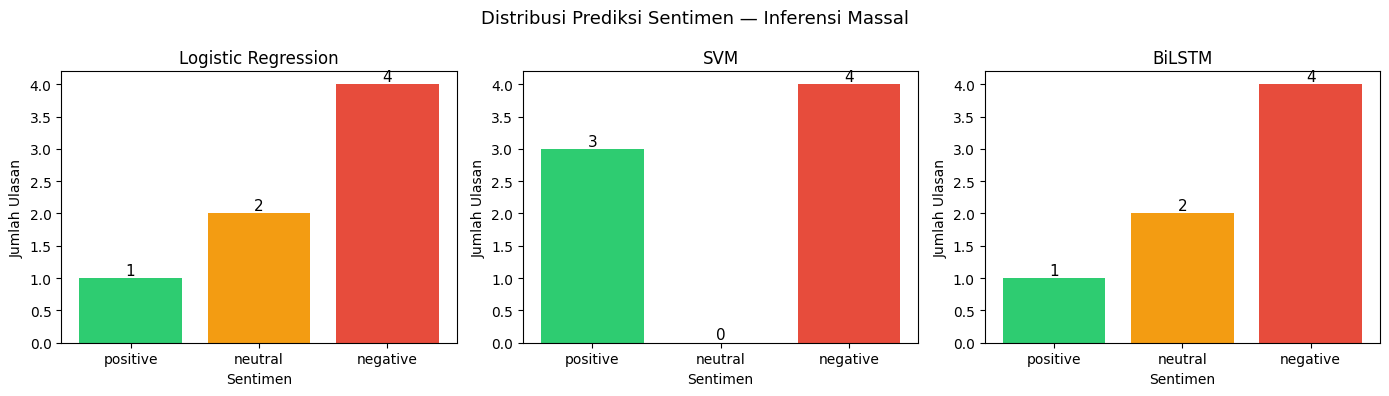

In [17]:
# Ringkasan distribusi hasil prediksi
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
label_order = ['positive', 'neutral', 'negative']
colors = ['#2ecc71', '#f39c12', '#e74c3c']

for ax, col, title in zip(
    axes,
    ['prediksi_lr', 'prediksi_svm', 'prediksi_lstm'],
    ['Logistic Regression', 'SVM', 'BiLSTM']
):
    counts = df_hasil[col].value_counts().reindex(label_order, fill_value=0)
    ax.bar(counts.index, counts.values,
           color=[colors[label_order.index(l)] for l in counts.index])
    ax.set_title(title)
    ax.set_ylabel('Jumlah Ulasan')
    ax.set_xlabel('Sentimen')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 0.05, str(v), ha='center', fontsize=11)

plt.suptitle('Distribusi Prediksi Sentimen — Inferensi Massal', fontsize=13)
plt.tight_layout()
plt.show()